# K-Nearest Neighbors - Dinali L. D. G. N. (IT25102054)

## 1. Model Suitability

**Why KNN for Wisconsin Breast Cancer?**

- Instance-based / lazy learner - makes decisions based on local neighbourhood.
- Dataset is small (~700 samples) then KNN is computationally feasible.
- After StandardScaler, Euclidean distance is meaningful.
- Non-parametric - can capture complex decision boundaries without assuming linearity.
- Easy to understand and tune (mainly `n_neighbors` and distance weight).


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
df = df.drop(columns=['Sample_code_number'], errors='ignore')
feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]
X_orig = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values
y = df['Class'].values
print("Original features shape:", X_orig.shape)
print("Scaled features shape  :", X_scaled.shape)
print("Class balance          :", np.bincount(y))

Original features shape: (699, 9)
Scaled features shape  : (699, 9)
Class balance          : [458 241]


In [ ]:
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)
X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print("Train size:", X_train_orig.shape[0], "| Test size:", X_test_orig.shape[0])
print("Train class distribution:", np.bincount(y_train))

Train size: 559 | Test size: 140
Train class distribution: [366 193]


In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.0
    }
    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, y_pred, y_prob

## 2. Implementation - KNN Varieties

| Variety | Description |
|---------|-------------|
| V1 Baseline | k=5, uniform weights, scaled |
| V2 Manual | k=3, distance weights |
| V3 GridSearchCV | Search over k, weights, metric |
| V4 Unscaled | Best params on original features |


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# V1 Baseline
knn_v1 = KNeighborsClassifier(n_neighbors=5, weights='uniform')
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_model(
    knn_v1, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V1: KNN (k=5, uniform, Scaled)"
)


========== V1: KNN (k=5, uniform, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.96      0.96      0.96        92
Malignant (1)       0.92      0.92      0.92        48

     accuracy                           0.94       140
    macro avg       0.94      0.94      0.94       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
 [[88  4]
 [ 4 44]]
ROC-AUC: 0.9740


In [ ]:
# V2 Manual
knn_v2 = KNeighborsClassifier(n_neighbors=3, weights='distance', metric='euclidean')
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_model(
    knn_v2, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V2: KNN (k=3, distance, Scaled)"
)


========== V2: KNN (k=3, distance, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.96      0.96      0.96        92
Malignant (1)       0.92      0.92      0.92        48

     accuracy                           0.94       140
    macro avg       0.94      0.94      0.94       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
 [[88  4]
 [ 4 44]]
ROC-AUC: 0.9622


In [ ]:
# V3 GridSearchCV
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_knn.fit(X_train_scaled, y_train)
print("Best parameters :", grid_knn.best_params_)
print("Best CV F1 score:", grid_knn.best_score_)

knn_v3 = grid_knn.best_estimator_
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_model(
    knn_v3, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V3: KNN (GridSearchCV Best)"
)

Fitting 5 folds for each of 42 candidates, totalling 210 fits
Best parameters : {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Best CV F1 score: 0.9692190265874476

========== V3: KNN (GridSearchCV Best) ==========
               precision    recall  f1-score   support

   Benign (0)       0.95      0.96      0.95        92
Malignant (1)       0.91      0.90      0.91        48

     accuracy                           0.94       140
    macro avg       0.93      0.93      0.93       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
 [[88  4]
 [ 5 43]]
ROC-AUC: 0.9583


In [ ]:
# V4 Unscaled (distance-based then usually worse)
knn_v4 = KNeighborsClassifier(**grid_knn.best_params_)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_model(
    knn_v4, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V4: KNN (Best params, Unscaled)"
)


========== V4: KNN (Best params, Unscaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.95      0.96      0.95        92
Malignant (1)       0.91      0.90      0.91        48

     accuracy                           0.94       140
    macro avg       0.93      0.93      0.93       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
 [[88  4]
 [ 5 43]]
ROC-AUC: 0.9589


## 3. Comparison

In [ ]:
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4]).set_index('Model')
print(results_df.round(4).to_string())
print("\n>>> Best F1:", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")

                                 Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                          
V1: KNN (k=5, uniform, Scaled)     0.9429     0.9167  0.9167    0.9167   0.9740
V2: KNN (k=3, distance, Scaled)    0.9429     0.9167  0.9167    0.9167   0.9622
V3: KNN (GridSearchCV Best)        0.9357     0.9149  0.8958    0.9053   0.9583
V4: KNN (Best params, Unscaled)    0.9357     0.9149  0.8958    0.9053   0.9589

>>> Best F1: V1: KNN (k=5, uniform, Scaled) (0.9167)


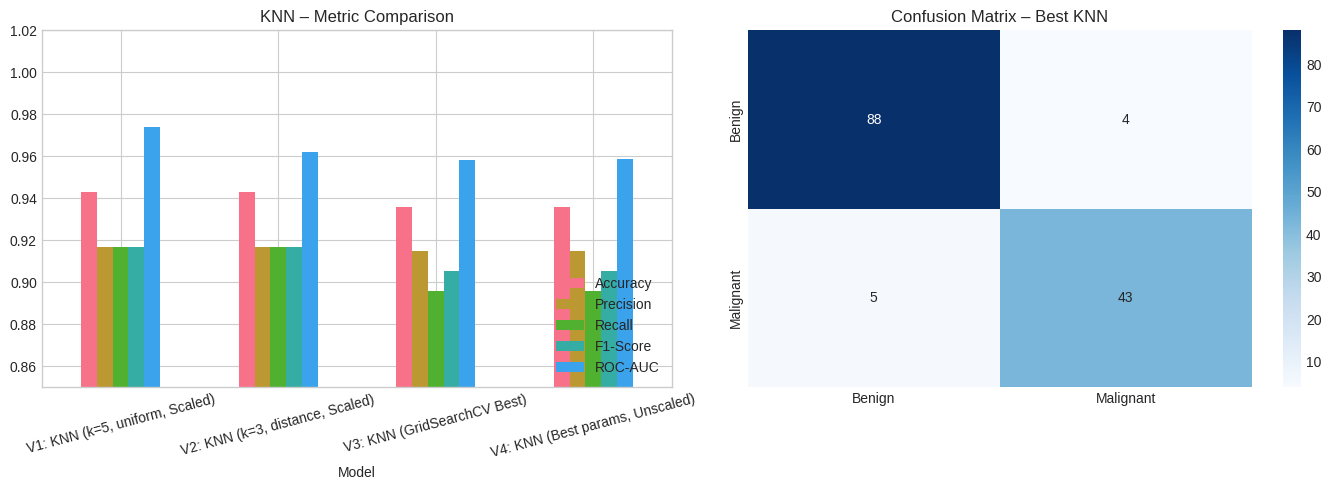

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
results_df[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('KNN - Metric Comparison')
axes[0].set_ylim(0.85, 1.02)
axes[0].legend(loc='lower right')
cm = confusion_matrix(y_test, y_pred_v3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
axes[1].set_title('Confusion Matrix - Best KNN')
plt.tight_layout()
plt.show()

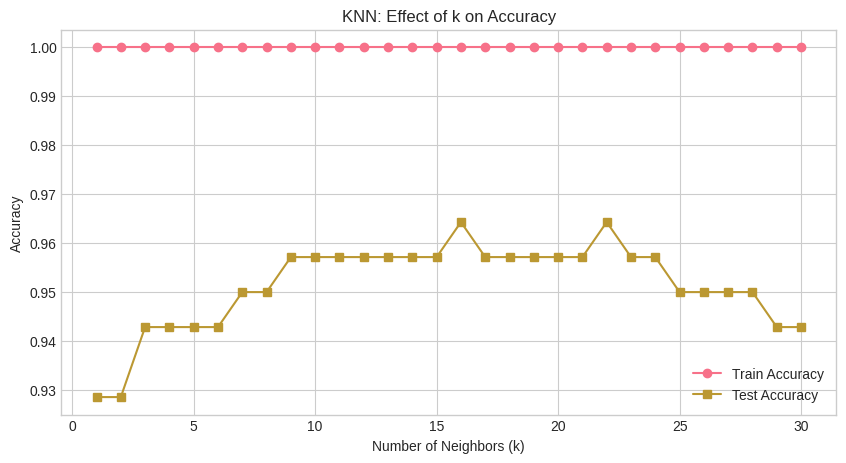

In [ ]:
# Effect of k on performance (extra analysis)
k_range = range(1, 31)
train_scores, test_scores = [], []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled, y_test))

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_scores, 'o-', label='Train Accuracy')
plt.plot(k_range, test_scores, 's-', label='Test Accuracy')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN: Effect of k on Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## 4. Validation Method
Stratified 80/20 + Stratified 5-Fold CV, scoring = F1.

## 5. Conclusion
- Scaled features are mandatory for KNN.
- Optimal k is usually odd (3-11) with distance weighting.
- **Recommended**: Variety 3 (GridSearchCV on scaled data).

## 6. Limitations & Improvements
| Limitation | Improvement |
|------------|-------------|
| Slow prediction on large data | Use Ball-tree / KD-tree or approximate NN |
| Sensitive to irrelevant features | Feature selection (already done) |
| Curse of dimensionality | Dimensionality reduction / more data |
| Choice of k critical | Cross-validation (done) |
